In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import preprocessing as pp, feature_engineering as fe, pipeline as P
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
def show(name, w=800): display(Image(filename=str(FIG / name), width=w))

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 11 SHAP explainability
TreeSHAP on XGBoost. SHAP explains the *model*, not the real world: no causal or clinical claims.

In [2]:
pd.read_csv(TAB/'shap_importance.csv', index_col=0).round(4).head(15)

,Low,Medium,High,Overall mean |SHAP|
log_mspb_episodes,0.1357,0.1827,0.1171,0.1452
log_function_cases,0.1354,0.1271,0.1248,0.1291
n_irf_in_state,0.1379,0.0696,0.1496,0.1190
facility_age_years,0.1005,0.0865,0.1097,0.0989
log_eligible_stays,0.1094,0.0859,0.1004,0.0986
ownership_For profit,0.1726,0.0094,0.0600,0.0807
cms_region_6,0.0316,0.0188,0.1054,0.0519
name_encompass_chain,0.0983,0.0109,0.0379,0.0490
name_has_rehab,0.0841,0.0139,0.0375,0.0451
ownership_Non-profit,0.0542,0.0059,0.0669,0.0423


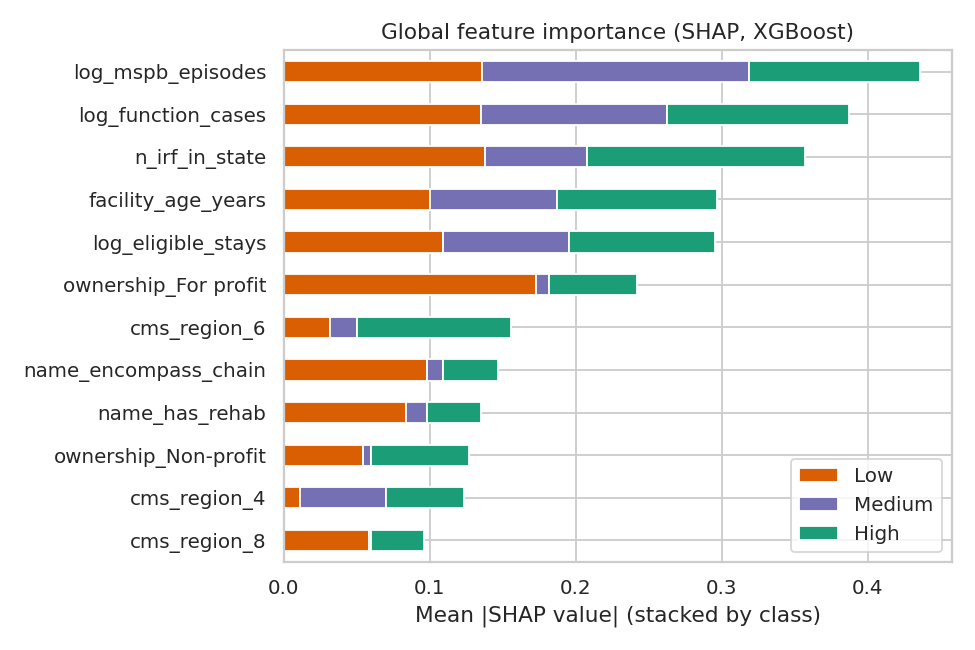

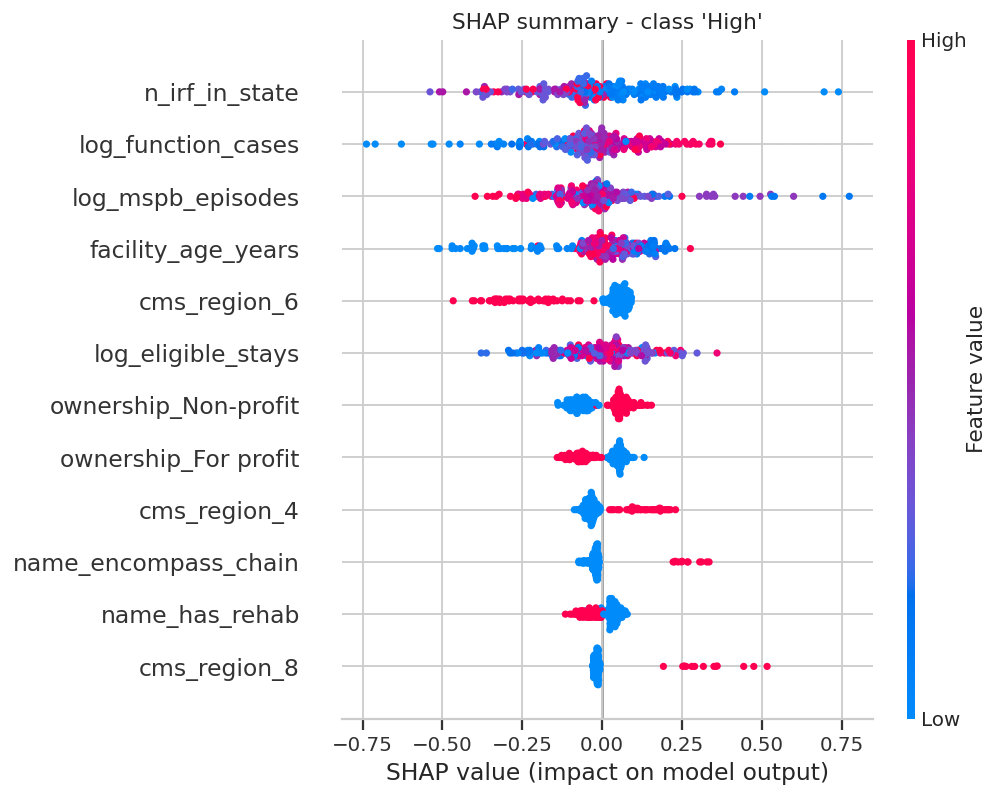

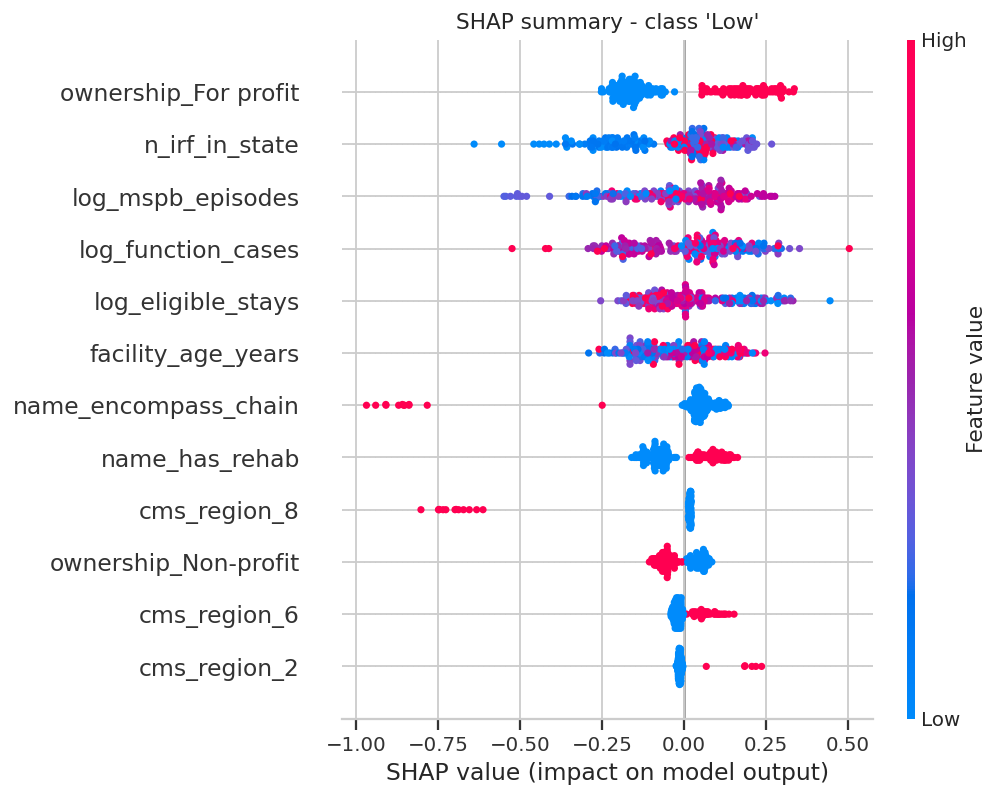

In [3]:
show('fig18_shap_importance.png', 600); show('fig19_shap_beeswarm_high.png', 650); show('fig20_shap_beeswarm_low.png', 650)

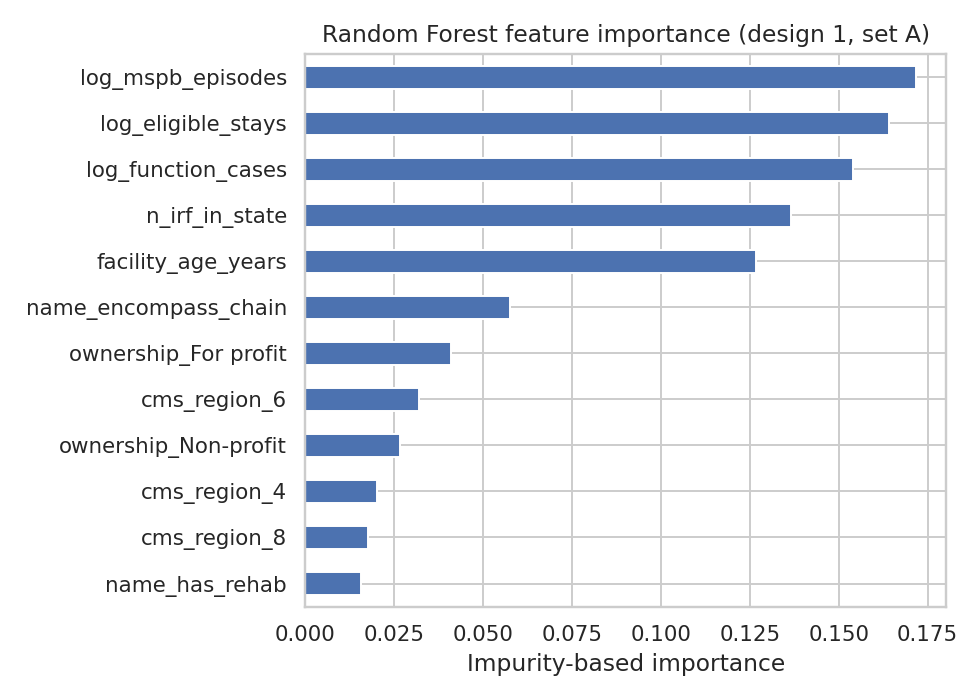

In [4]:
show('fig17_rf_importance.png', 550)

### Local explanations

In [5]:
local = json.load(open(TAB/'shap_local.json')); pd.DataFrame(local)

,category,CCN,facility,pred_prob,top_positive,top_negative
0,Low,193086,LEESVILLE REHABILITATION HOSPITAL,0.801373,"{'log_eligible_stays': 0.326, 'log_function_ca...","{'log_mspb_episodes': -0.142, 'facility_age_ye..."
1,Medium,45TA23,KINDRED HOSPITAL HOUSTON MEDICAL CENTER,0.732427,"{'log_function_cases': 0.402, 'log_mspb_episod...","{'facility_age_years': -0.06, 'ownership_For p..."
2,High,103032,ENCOMPASS HEALTH REHAB HOSPITAL OF TREASURE COAST,0.680492,"{'name_encompass_chain': 0.267, 'log_mspb_epis...","{'n_irf_in_state': -0.14, 'ownership_Non-profi..."


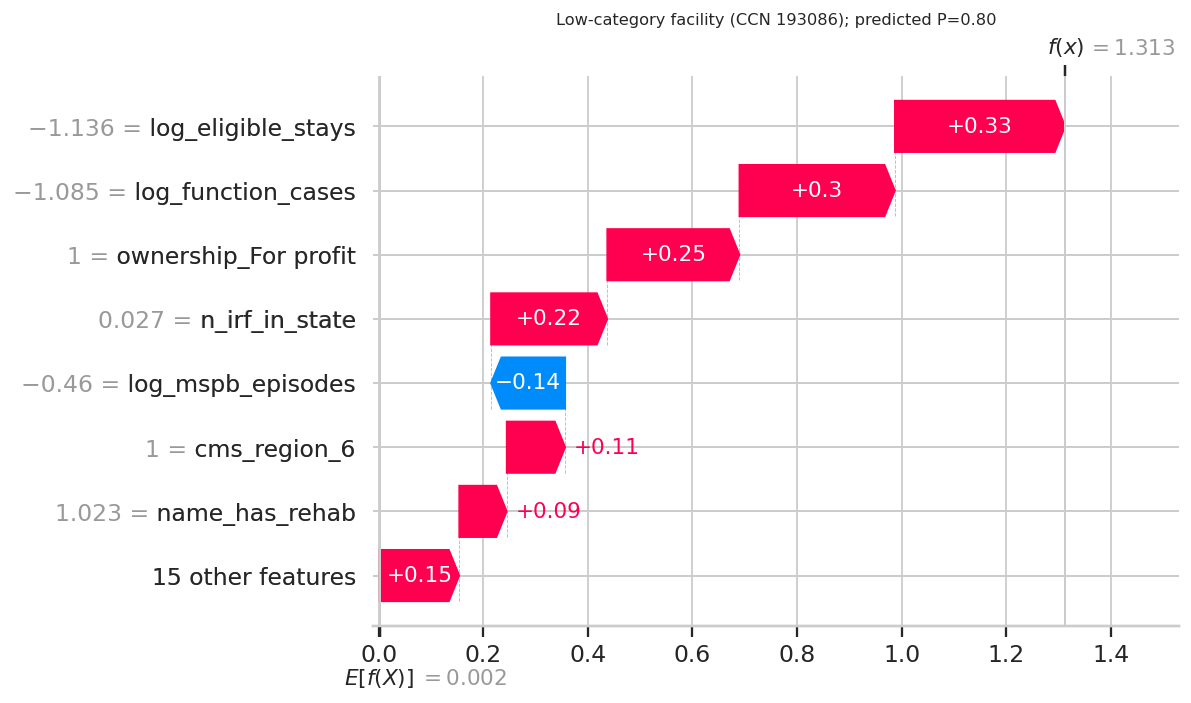

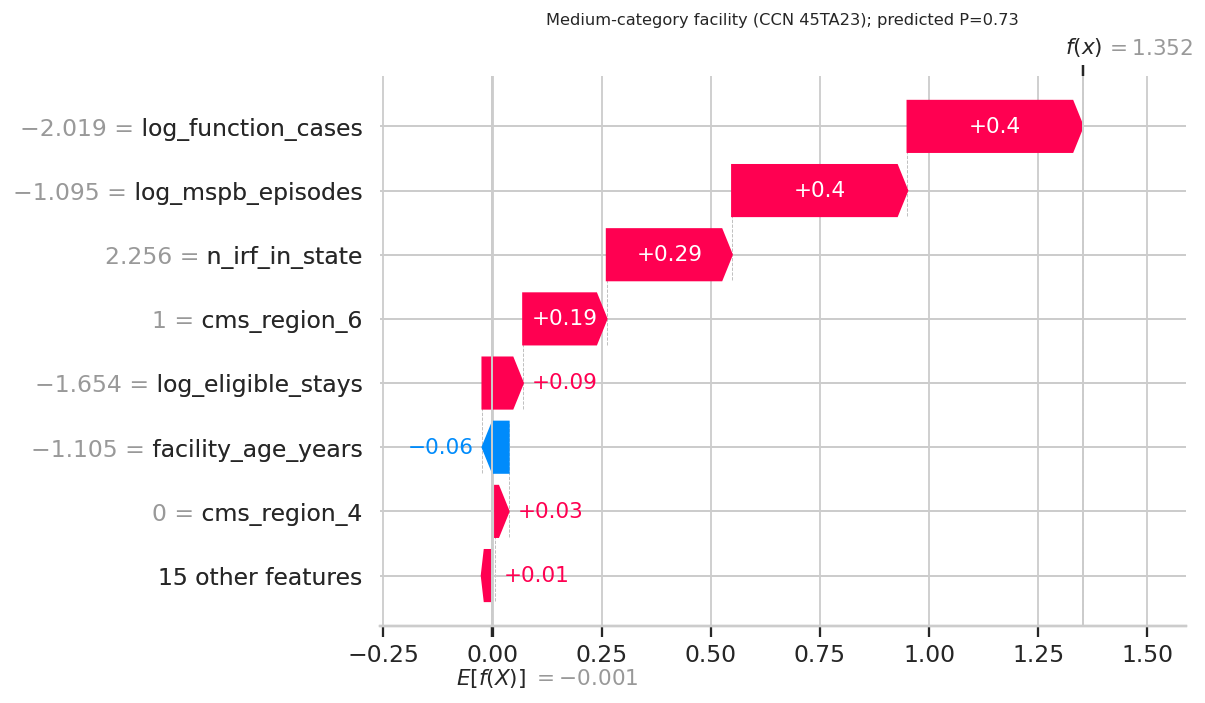

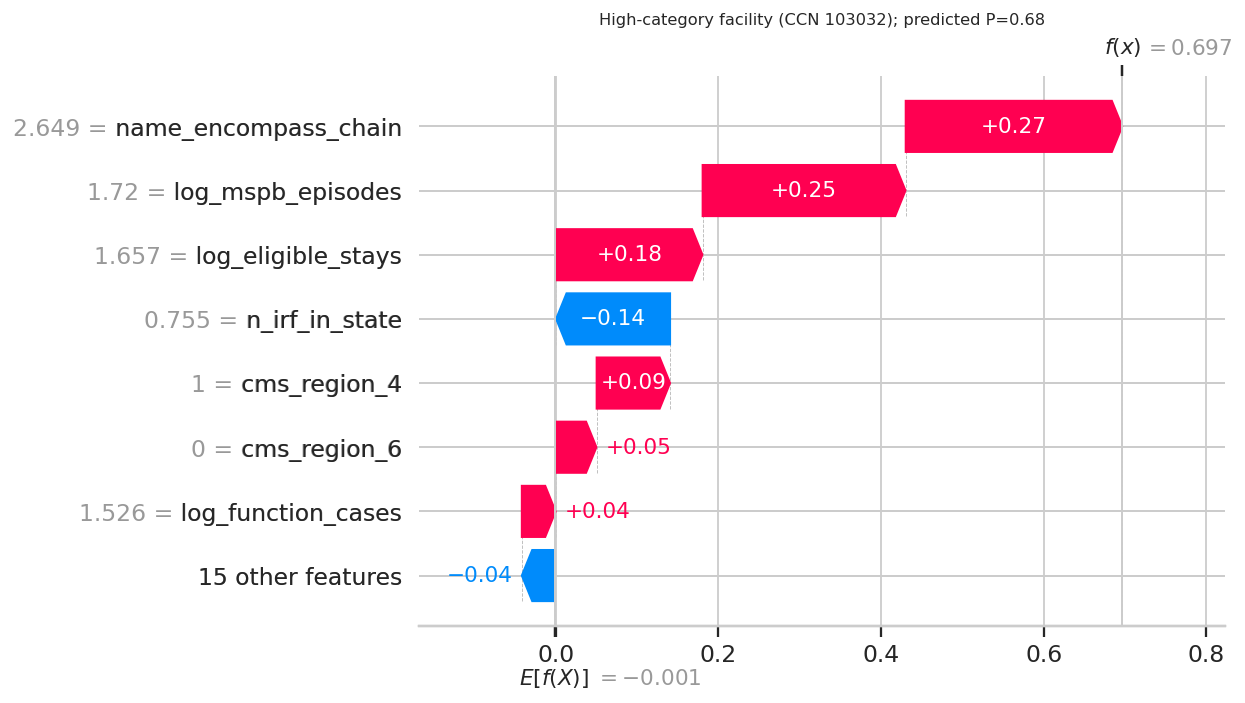

In [6]:
for c in ['low','medium','high']: show(f'fig21_shap_local_{c}.png', 650)

### Design 2

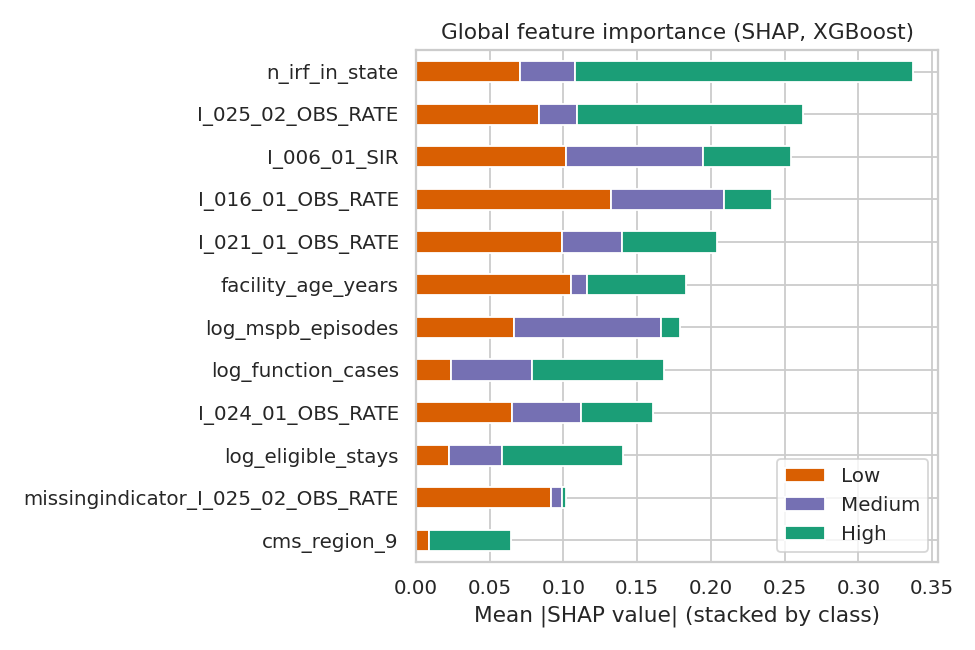

,Low,Medium,High,Overall mean |SHAP|
n_irf_in_state,0.0705,0.0370,0.2297,0.1124
I_025_02_OBS_RATE,0.0832,0.0257,0.1538,0.0875
I_006_01_SIR,0.1017,0.0927,0.0599,0.0848
I_016_01_OBS_RATE,0.1323,0.0762,0.0327,0.0804
I_021_01_OBS_RATE,0.0988,0.0409,0.0645,0.0681
facility_age_years,0.1048,0.0115,0.0672,0.0611
log_mspb_episodes,0.0664,0.0997,0.0129,0.0597
log_function_cases,0.0236,0.0552,0.0891,0.0560
I_024_01_OBS_RATE,0.0650,0.0466,0.0494,0.0537
log_eligible_stays,0.0223,0.0360,0.0821,0.0468


In [7]:
show('fig23_shap_importance_design2.png', 600); pd.read_csv(TAB/'shap_importance_design2.csv', index_col=0).round(4).head(12)